In [3]:
# =====================================================================
# PHASE 4b - VALIDATION-ONLY CHECKS ON THE SKELETON MODELS (paste into ONE Colab cell)
# Self-contained: needs only /content/skeleton_clean and /content/split_manifest.csv
# The TEST split is never loaded into tensors and never evaluated here.
# =====================================================================
import os, glob, copy, time
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F

CLEAN_ROOT = "/content/skeleton_clean"
MANIFEST   = "/content/split_manifest.csv"
LOG_DIR    = "/content/results_skeleton"
SEEDS = [42, 43, 44, 45, 46]
BATCH, MAX_EPOCHS, PATIENCE, LR, WD = 64, 150, 20, 1e-3, 1e-4
NOISE_STD, SCALE_JIT = 0.02, 0.10
CLASS_NAMES = ["backhand", "backhand2hands", "backhand_slice", "backhand_volley", "flat_service",
               "forehand_flat", "forehand_openstands", "forehand_slice", "forehand_volley",
               "kick_service", "slice_service", "smash"]
SWAP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
os.makedirs(LOG_DIR, exist_ok=True)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CONFIGS = [   # name, model, use duration, mirror probability, frames shuffled in time (train + val)
    dict(name="A single pose (baseline)",        model="A", dur=False, mirror=0.5, shuf=False),
    dict(name="A  no mirror",                    model="A", dur=False, mirror=0.0, shuf=False),
    dict(name="B sequence (baseline)",           model="B", dur=True,  mirror=0.5, shuf=False),
    dict(name="B  no duration",                  model="B", dur=False, mirror=0.5, shuf=False),
    dict(name="B  no mirror",                    model="B", dur=True,  mirror=0.0, shuf=False),
    dict(name="B  frames shuffled in time",      model="B", dur=True,  mirror=0.5, shuf=True),
]

# ---------------- data (train + val only) ----------------
assert sorted(d for d in os.listdir(CLEAN_ROOT) if os.path.isdir(f"{CLEAN_ROOT}/{d}")) == CLASS_NAMES
man = pd.read_csv(MANIFEST)
sc = next(c for c in man.columns if "subject" in c.lower()); pc = next(c for c in man.columns if "split" in c.lower())
ns = lambda s: str(s).strip().lower() if str(s).strip().lower().startswith("p") else f"p{str(s).strip().lower()}"
subj2split = man.assign(_s=man[sc].map(ns)).drop_duplicates("_s").set_index("_s")[pc].to_dict()
recs = []
for ci, cname in enumerate(CLASS_NAMES):
    for p in sorted(glob.glob(f"{CLEAN_ROOT}/{cname}/*.npz")):
        d = np.load(p); stem = os.path.splitext(os.path.basename(p))[0]; subj = stem.split("_")[0].lower()
        recs.append(dict(seq=d["seq"], mid=d["mid_pose"], dur=float(d["duration"]), y=ci, subj=subj, split=subj2split[subj]))
df = pd.DataFrame(recs)
sets = {s: set(df[df.split == s].subj) for s in df.split.unique()}
assert len(df) == 1980 and sorted(df.groupby("split").size().tolist()) == [288, 288, 1404]
nm = list(sets); assert all(not (sets[a] & sets[b]) for i, a in enumerate(nm) for b in nm[i + 1:])
print("data + split check passed (no subject in two splits); test split not used\n")

def tens(split):
    s = df[df.split == split]
    return (torch.tensor(np.stack(s.seq), dtype=torch.float32), torch.tensor(np.stack(s.mid), dtype=torch.float32),
            torch.tensor(s.dur.values, dtype=torch.float32), torch.tensor(s.y.values, dtype=torch.long))
D = {s: tens(s) for s in ("train", "val")}
mu, sd_ = D["train"][2].mean(), D["train"][2].std()                 # duration statistics from TRAIN only
for s in D: D[s] = (D[s][0], D[s][1], (D[s][2] - mu) / sd_, D[s][3])

# ---------------- models + helpers ----------------
class PoseMLP(nn.Module):
    def __init__(self, n=12):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(34, 128), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n))
    def forward(self, x, dur=None): return self.net(x)

class SeqCNN(nn.Module):
    def __init__(self, n=12, use_dur=True):
        super().__init__()
        self.use_dur = use_dur
        self.conv = nn.Sequential(
            nn.Conv1d(34, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 5, stride=2, padding=2), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 128, 3, stride=2, padding=1), nn.BatchNorm1d(128), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(256 + int(use_dur), 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n))
    def forward(self, x, dur=None):
        h = self.conv(x.flatten(2).transpose(1, 2))
        h = torch.cat([h.mean(2), h.amax(2)], 1)
        if self.use_dur: h = torch.cat([h, dur.unsqueeze(1)], 1)
        return self.head(h)

def augment(x, mirror_p):
    B = x.shape[0]
    if mirror_p > 0:
        flip = torch.rand(B, device=x.device) < mirror_p
        if flip.any():
            xf = x[flip].clone(); xf[..., 0] = -xf[..., 0]; x[flip] = xf[..., SWAP, :]
    s = 1 + (torch.rand(B, device=x.device) * 2 - 1) * SCALE_JIT
    x = x * s.view(B, *([1] * (x.dim() - 1)))
    return x + torch.randn_like(x) * NOISE_STD

def tshuffle(x, gen=None):                       # scramble the order of the 64 time steps, per video
    B, T = x.shape[:2]
    idx = torch.rand(B, T, generator=gen).argsort(1).to(x.device)
    return torch.gather(x, 1, idx[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3]))

@torch.no_grad()
def evaluate(model, X, d, y):
    model.eval(); lg = model(X, d)
    return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item(), lg.argmax(1)

def acc_shuffled(model, X, d, y, reps=5):        # accuracy when a trained model sees scrambled frame order
    return float(np.mean([evaluate(model, tshuffle(X, torch.Generator().manual_seed(1000 + r)), d, y)[1] for r in range(reps)]))

def run(cfg, seed, keep_preds=False):
    torch.manual_seed(seed); np.random.seed(seed); g = torch.Generator().manual_seed(seed)
    isB = cfg["model"] == "B"; which = 0 if isB else 1
    model = (SeqCNN(use_dur=cfg["dur"]) if isB else PoseMLP()).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    Xtr, dtr, ytr = D["train"][which].to(dev), D["train"][2].to(dev), D["train"][3].to(dev)
    Xva, dva, yva = D["val"][which].to(dev), D["val"][2].to(dev), D["val"][3].to(dev)
    Xev = tshuffle(Xva, torch.Generator().manual_seed(999)) if cfg["shuf"] else Xva
    best, best_state, bad, best_ep, tr_acc = (-1.0, 9e9), None, 0, 0, 0.0
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); perm = torch.randperm(len(Xtr), generator=g).to(dev); tc = 0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            xb = augment(Xtr[idx].clone(), cfg["mirror"])
            if cfg["shuf"]: xb = tshuffle(xb)
            lg = model(xb, dtr[idx]); loss = F.cross_entropy(lg, ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            tc += (lg.argmax(1) == ytr[idx]).sum().item()
        vl, va, _ = evaluate(model, Xev, dva, yva)
        if (va, -vl) > (best[0], -best[1]):
            best, best_state, bad, best_ep, tr_acc = (va, vl), copy.deepcopy(model.state_dict()), 0, ep, tc / len(Xtr)
        else:
            bad += 1
        if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    _, va, pr = evaluate(model, Xev, dva, yva)
    out = dict(config=cfg["name"], seed=seed, best_val=va, best_epoch=best_ep, train_acc=tr_acc,
               val_shuffled=acc_shuffled(model, Xva, dva, yva) if isB else np.nan)
    if keep_preds: out["preds"] = pr.cpu().numpy()
    return out

# ---------------- run everything ----------------
t0 = time.time(); rows, preds = [], {}
for cfg in CONFIGS:
    for sd in SEEDS:
        r = run(cfg, sd, keep_preds=(sd == SEEDS[0]))
        if "preds" in r: preds[cfg["name"]] = r.pop("preds")
        rows.append(r)
        print(f"{cfg['name']:30s} seed {sd}: val acc {r['best_val']:.3f} (epoch {r['best_epoch']:3d}) | {(time.time() - t0) / 60:.1f} min elapsed")
res = pd.DataFrame(rows); res.to_csv(f"{LOG_DIR}/ablation_runs.csv", index=False)

print("\n" + "=" * 100)
print("VALIDATION RESULTS, mean +- std over 5 seeds (test set NOT used). Pixel baseline (ResNet50, 1 frame): 0.2639")
print(f"{'config':30s}{'val acc':>16s}{'train acc':>12s}{'gap':>8s}{'val acc, frames scrambled':>28s}{'median best epoch':>20s}")
for name, g_ in res.groupby("config", sort=False):
    sh = g_.val_shuffled.mean()
    print(f"{name:30s}{g_.best_val.mean():>9.3f} +- {g_.best_val.std():.3f}{g_.train_acc.mean():>12.3f}"
          f"{g_.train_acc.mean() - g_.best_val.mean():>8.3f}{('n/a' if np.isnan(sh) else f'{sh:.3f}'):>28s}{g_.best_epoch.median():>20.0f}")
print("=" * 100)

yv = D["val"][3].numpy(); pa, pb = preds[CONFIGS[0]["name"]], preds[CONFIGS[2]["name"]]
print("\nPer-class validation recall (seed 42 baselines)")
print(f"{'class':22s}{'A pose':>9s}{'B sequence':>12s}{'videos':>8s}")
for c, n in enumerate(CLASS_NAMES):
    print(f"{n:22s}{(pa[yv == c] == c).mean():>9.2f}{(pb[yv == c] == c).mean():>12.2f}{int((yv == c).sum()):>8d}")
cm = np.zeros((12, 12), int); np.add.at(cm, (yv, pb), 1)
pairs = sorted([(cm[i, j], i, j) for i in range(12) for j in range(12) if i != j], reverse=True)[:8]
print("\nMost common mistakes of Model B (true -> predicted : count)")
for n, i, j in pairs: print(f"  {CLASS_NAMES[i]} -> {CLASS_NAMES[j]} : {n}")
print(f"\nSaved: {LOG_DIR}/ablation_runs.csv")

data + split check passed (no subject in two splits); test split not used

A single pose (baseline)       seed 42: val acc 0.427 (epoch  83) | 0.2 min elapsed
A single pose (baseline)       seed 43: val acc 0.410 (epoch  57) | 0.3 min elapsed
A single pose (baseline)       seed 44: val acc 0.399 (epoch  39) | 0.3 min elapsed
A single pose (baseline)       seed 45: val acc 0.392 (epoch  36) | 0.4 min elapsed
A single pose (baseline)       seed 46: val acc 0.427 (epoch  72) | 0.5 min elapsed
A  no mirror                   seed 42: val acc 0.413 (epoch  63) | 0.5 min elapsed
A  no mirror                   seed 43: val acc 0.396 (epoch  26) | 0.6 min elapsed
A  no mirror                   seed 44: val acc 0.410 (epoch  35) | 0.6 min elapsed
A  no mirror                   seed 45: val acc 0.396 (epoch  22) | 0.7 min elapsed
A  no mirror                   seed 46: val acc 0.413 (epoch  74) | 0.7 min elapsed
B sequence (baseline)          seed 42: val acc 0.646 (epoch  25) | 1.5 min elapsed
B

In [4]:
# =====================================================================
# PHASE 5 - FINAL TEST EVALUATION (RUN ONCE) - skeleton models
# Paste into ONE Colab cell. Needs /content/skeleton_clean and /content/split_manifest.csv.
#
# Order of events (this is the test-set discipline):
#   1. train every model using TRAIN + VALIDATION only; settings are frozen below
#   2. only AFTER all models are trained and saved, build the test tensors
#   3. evaluate each frozen model on the test set exactly once and report
# Do NOT change any setting after seeing the test numbers.
# =====================================================================
import os, glob, copy, time
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

CLEAN_ROOT = "/content/skeleton_clean"
MANIFEST   = "/content/split_manifest.csv"
OUT_DIR    = "/content/models_skeleton"
LOG_DIR    = "/content/results_skeleton"
LOCK       = f"{LOG_DIR}/TEST_ALREADY_RUN.txt"
FORCE_RERUN = False
SEEDS = [42, 43, 44, 45, 46]
BATCH, MAX_EPOCHS, PATIENCE, LR, WD = 64, 150, 20, 1e-3, 1e-4
NOISE_STD, SCALE_JIT = 0.02, 0.10
CLASS_NAMES = ["backhand", "backhand2hands", "backhand_slice", "backhand_volley", "flat_service",
               "forehand_flat", "forehand_openstands", "forehand_slice", "forehand_volley",
               "kick_service", "slice_service", "smash"]
SWAP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]

FINAL = [   # settings FROZEN from the validation checks: mirror on, swing duration off
    dict(tag="A",       name="A  single pose",                model="A", dur=False, mirror=0.5, shuf=False),
    dict(tag="B",       name="B  pose sequence",              model="B", dur=False, mirror=0.5, shuf=False),
    dict(tag="B_shuf",  name="B  control: frames shuffled",   model="B", dur=False, mirror=0.5, shuf=True),
]
# the later take of each pair of identical videos found earlier (for a sensitivity check only)
DUP_LATER = {"p47_backhand_s3", "p55_backhand2h_s3", "p55_bslice_s3", "p55_serflat_s3", "p13_foreflat_s3",
             "p55_foreflat_s3", "p55_foreopen_s3", "p55_fslice_s3", "p50_fvolley_s2"}

os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(LOG_DIR, exist_ok=True)
if os.path.exists(LOCK) and not FORCE_RERUN:
    raise RuntimeError("The test set was already evaluated in this session. Re-running would break the test-set rule. "
                       "Use the saved results instead.")
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- data: train + val only for now ----------------
assert sorted(d for d in os.listdir(CLEAN_ROOT) if os.path.isdir(f"{CLEAN_ROOT}/{d}")) == CLASS_NAMES
man = pd.read_csv(MANIFEST)
sc = next(c for c in man.columns if "subject" in c.lower()); pc = next(c for c in man.columns if "split" in c.lower())
ns = lambda s: str(s).strip().lower() if str(s).strip().lower().startswith("p") else f"p{str(s).strip().lower()}"
subj2split = man.assign(_s=man[sc].map(ns)).drop_duplicates("_s").set_index("_s")[pc].to_dict()
recs = []
for ci, cname in enumerate(CLASS_NAMES):
    for p in sorted(glob.glob(f"{CLEAN_ROOT}/{cname}/*.npz")):
        d = np.load(p); stem = os.path.splitext(os.path.basename(p))[0]; subj = stem.split("_")[0].lower()
        recs.append(dict(seq=d["seq"], mid=d["mid_pose"], dur=float(d["duration"]), y=ci, subj=subj, split=subj2split[subj], stem=stem))
df = pd.DataFrame(recs)
sets = {s: set(df[df.split == s].subj) for s in df.split.unique()}
assert len(df) == 1980 and sorted(df.groupby("split").size().tolist()) == [288, 288, 1404]
nm = list(sets); assert all(not (sets[a] & sets[b]) for i, a in enumerate(nm) for b in nm[i + 1:])
print("split check passed (no subject in two splits). Test tensors are NOT built yet.\n")

def tens(split):
    s = df[df.split == split]
    return (torch.tensor(np.stack(s.seq), dtype=torch.float32), torch.tensor(np.stack(s.mid), dtype=torch.float32),
            torch.tensor(s.dur.values, dtype=torch.float32), torch.tensor(s.y.values, dtype=torch.long))
D = {s: tens(s) for s in ("train", "val")}
mu, sd_ = D["train"][2].mean(), D["train"][2].std()                  # statistics from TRAIN only
std_dur = lambda t: (t[0], t[1], (t[2] - mu) / sd_, t[3])
D = {s: std_dur(D[s]) for s in D}

# ---------------- models + helpers (identical to the validation checks) ----------------
class PoseMLP(nn.Module):
    def __init__(self, n=12):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(34, 128), nn.ReLU(), nn.Dropout(0.3),
                                 nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n))
    def forward(self, x, dur=None): return self.net(x)

class SeqCNN(nn.Module):
    def __init__(self, n=12, use_dur=True):
        super().__init__()
        self.use_dur = use_dur
        self.conv = nn.Sequential(
            nn.Conv1d(34, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 5, stride=2, padding=2), nn.BatchNorm1d(128), nn.ReLU(),
            nn.Conv1d(128, 128, 3, stride=2, padding=1), nn.BatchNorm1d(128), nn.ReLU())
        self.head = nn.Sequential(nn.Linear(256 + int(use_dur), 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n))
    def forward(self, x, dur=None):
        h = self.conv(x.flatten(2).transpose(1, 2))
        h = torch.cat([h.mean(2), h.amax(2)], 1)
        if self.use_dur: h = torch.cat([h, dur.unsqueeze(1)], 1)
        return self.head(h)

build = lambda cfg: SeqCNN(use_dur=cfg["dur"]) if cfg["model"] == "B" else PoseMLP()
which = lambda cfg: 0 if cfg["model"] == "B" else 1

def augment(x, mirror_p):
    B = x.shape[0]
    if mirror_p > 0:
        flip = torch.rand(B, device=x.device) < mirror_p
        if flip.any():
            xf = x[flip].clone(); xf[..., 0] = -xf[..., 0]; x[flip] = xf[..., SWAP, :]
    s = 1 + (torch.rand(B, device=x.device) * 2 - 1) * SCALE_JIT
    x = x * s.view(B, *([1] * (x.dim() - 1)))
    return x + torch.randn_like(x) * NOISE_STD

def tshuffle(x, gen=None):
    B, T = x.shape[:2]
    idx = torch.rand(B, T, generator=gen).argsort(1).to(x.device)
    return torch.gather(x, 1, idx[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3]))

@torch.no_grad()
def evaluate(model, X, d, y):
    model.eval(); lg = model(X, d)
    return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item(), lg.argmax(1)

# ---------------- STEP 1: train all models (validation only) ----------------
def train_one(cfg, seed):
    torch.manual_seed(seed); np.random.seed(seed); g = torch.Generator().manual_seed(seed)
    model = build(cfg).to(dev); w = which(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    Xtr, dtr, ytr = D["train"][w].to(dev), D["train"][2].to(dev), D["train"][3].to(dev)
    Xva, dva, yva = D["val"][w].to(dev), D["val"][2].to(dev), D["val"][3].to(dev)
    Xev = tshuffle(Xva, torch.Generator().manual_seed(999)) if cfg["shuf"] else Xva
    best, state, bad, best_ep = (-1.0, 9e9), None, 0, 0
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); perm = torch.randperm(len(Xtr), generator=g).to(dev)
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            xb = augment(Xtr[idx].clone(), cfg["mirror"])
            if cfg["shuf"]: xb = tshuffle(xb)
            loss = F.cross_entropy(model(xb, dtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        vl, va, _ = evaluate(model, Xev, dva, yva)
        if (va, -vl) > (best[0], -best[1]):
            best, state, bad, best_ep = (va, vl), copy.deepcopy(model.state_dict()), 0, ep
        else:
            bad += 1
        if bad >= PATIENCE: break
    torch.save(state, f"{OUT_DIR}/final_{cfg['tag']}_seed{seed}.pt")
    return dict(cfg=cfg, seed=seed, state=state, val_acc=best[0], epoch=best_ep)

t0 = time.time(); trained = []
for cfg in FINAL:
    for sd in SEEDS:
        r = train_one(cfg, sd); trained.append(r)
        print(f"trained {cfg['name']:30s} seed {sd}: val acc {r['val_acc']:.3f} (epoch {r['epoch']}) | {(time.time()-t0)/60:.1f} min")
print("\nAll models trained and saved. Settings are now frozen. Building the test set...\n")

# ---------------- STEP 2: test set, evaluated ONCE per frozen model ----------------
T = std_dur(tens("test"))
stems_te = df[df.split == "test"].stem.values
y_te = T[3].numpy(); keep = ~np.isin(stems_te, list(DUP_LATER))
rows, preds_store = [], {}
for r in trained:
    cfg, w = r["cfg"], which(r["cfg"])
    model = build(cfg).to(dev); model.load_state_dict(r["state"])
    X, d, y = T[w].to(dev), T[2].to(dev), T[3].to(dev)
    if cfg["shuf"]: X = tshuffle(X, torch.Generator().manual_seed(999))
    _, acc, pr = evaluate(model, X, d, y); pr = pr.cpu().numpy()
    scr = np.nan
    if cfg["model"] == "B" and not cfg["shuf"]:     # scramble frame order at test time
        scr = float(np.mean([evaluate(model, tshuffle(X, torch.Generator().manual_seed(1000 + k)), d, y)[1] for k in range(5)]))
    rows.append(dict(config=cfg["name"], seed=r["seed"], val_acc=r["val_acc"], test_acc=acc,
                     macro_f1=f1_score(y_te, pr, average="macro", labels=list(range(12)), zero_division=0),
                     test_acc_no_duplicates=float((pr[keep] == y_te[keep]).mean()), test_acc_scrambled=scr))
    if r["seed"] == SEEDS[0]: preds_store[cfg["tag"]] = pr
res = pd.DataFrame(rows); res.to_csv(f"{LOG_DIR}/test_results_per_seed.csv", index=False)

n_te = len(y_te)
print("=" * 104)
print(f"FINAL TEST RESULTS - {n_te} videos from 8 people never used in training or tuning (mean +- std over 5 seeds)")
print(f"{'config':32s}{'test acc':>16s}{'~95% range*':>14s}{'macro F1':>10s}{'no duplicates':>15s}{'order scrambled':>17s}")
for name, g_ in res.groupby("config", sort=False):
    p = g_.test_acc.mean(); half = 1.96 * np.sqrt(p * (1 - p) / n_te); sc_ = g_.test_acc_scrambled.mean()
    print(f"{name:32s}{p:>9.3f} +- {g_.test_acc.std():.3f}{'+-' + format(half, '.3f'):>14s}{g_.macro_f1.mean():>10.3f}"
          f"{g_.test_acc_no_duplicates.mean():>15.3f}{('n/a' if np.isnan(sc_) else format(sc_, '.3f')):>17s}")
print("* range from test-set size alone (288 videos); it does not include the choice of which 8 people are in the test set")
print("-" * 104)
print("Earlier pixel results on the same test people: 1 frame 0.3056 | 3 frames scored one by one 0.2269 (864 frames) | 3 frames combined per video 0.3333")
print(f"Chance level: {1/12:.3f}")
print("=" * 104)

# ---------------- per-class results + confusion matrices (seed 42, decided in advance) ----------------
rep = {t: classification_report(y_te, preds_store[t], target_names=CLASS_NAMES, output_dict=True, zero_division=0) for t in ("A", "B")}
print("\nPer-class test results (seed 42)")
print(f"{'class':22s}{'A recall':>10s}{'B recall':>10s}{'B precision':>13s}{'B F1':>8s}{'videos':>8s}")
for n in CLASS_NAMES:
    print(f"{n:22s}{rep['A'][n]['recall']:>10.2f}{rep['B'][n]['recall']:>10.2f}{rep['B'][n]['precision']:>13.2f}{rep['B'][n]['f1-score']:>8.2f}{int(rep['B'][n]['support']):>8d}")
pd.DataFrame({t: pd.DataFrame(rep[t]).T for t in rep}).to_csv(f"{LOG_DIR}/test_per_class_seed42.csv")

for t, title in (("A", "Model A (single pose)"), ("B", "Model B (pose sequence)")):
    cm = confusion_matrix(y_te, preds_store[t], labels=list(range(12)))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{LOG_DIR}/test_confusion_{t}.csv")
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(f"Confusion Matrix - Test Set - {title}")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"); plt.tight_layout()
    fig.savefig(f"{LOG_DIR}/test_confusion_{t}.png", dpi=150, bbox_inches="tight"); plt.show()
    if t == "B":
        pairs = sorted([(cm[i, j], i, j) for i in range(12) for j in range(12) if i != j], reverse=True)[:8]
        print("Most common mistakes of Model B (true -> predicted : count)")
        for c, i, j in pairs: print(f"  {CLASS_NAMES[i]} -> {CLASS_NAMES[j]} : {c}")

with open(LOCK, "w") as f: f.write("Test set evaluated once. Do not re-run.")
print(f"\nSaved to {LOG_DIR}: test_results_per_seed.csv, test_per_class_seed42.csv, confusion matrices (.png/.csv)")

split check passed (no subject in two splits). Test tensors are NOT built yet.

trained A  single pose                 seed 42: val acc 0.427 (epoch 83) | 0.3 min
trained A  single pose                 seed 43: val acc 0.410 (epoch 57) | 0.4 min
trained A  single pose                 seed 44: val acc 0.399 (epoch 39) | 0.5 min
trained A  single pose                 seed 45: val acc 0.392 (epoch 36) | 0.5 min
trained A  single pose                 seed 46: val acc 0.427 (epoch 72) | 0.6 min
trained B  pose sequence               seed 42: val acc 0.670 (epoch 49) | 1.8 min
trained B  pose sequence               seed 43: val acc 0.656 (epoch 44) | 2.9 min
trained B  pose sequence               seed 44: val acc 0.660 (epoch 23) | 3.6 min
trained B  pose sequence               seed 45: val acc 0.677 (epoch 51) | 4.7 min
trained B  pose sequence               seed 46: val acc 0.674 (epoch 47) | 5.9 min
trained B  control: frames shuffled    seed 42: val acc 0.524 (epoch 23) | 6.6 min
trained

ValueError: If using all scalar values, you must pass an index

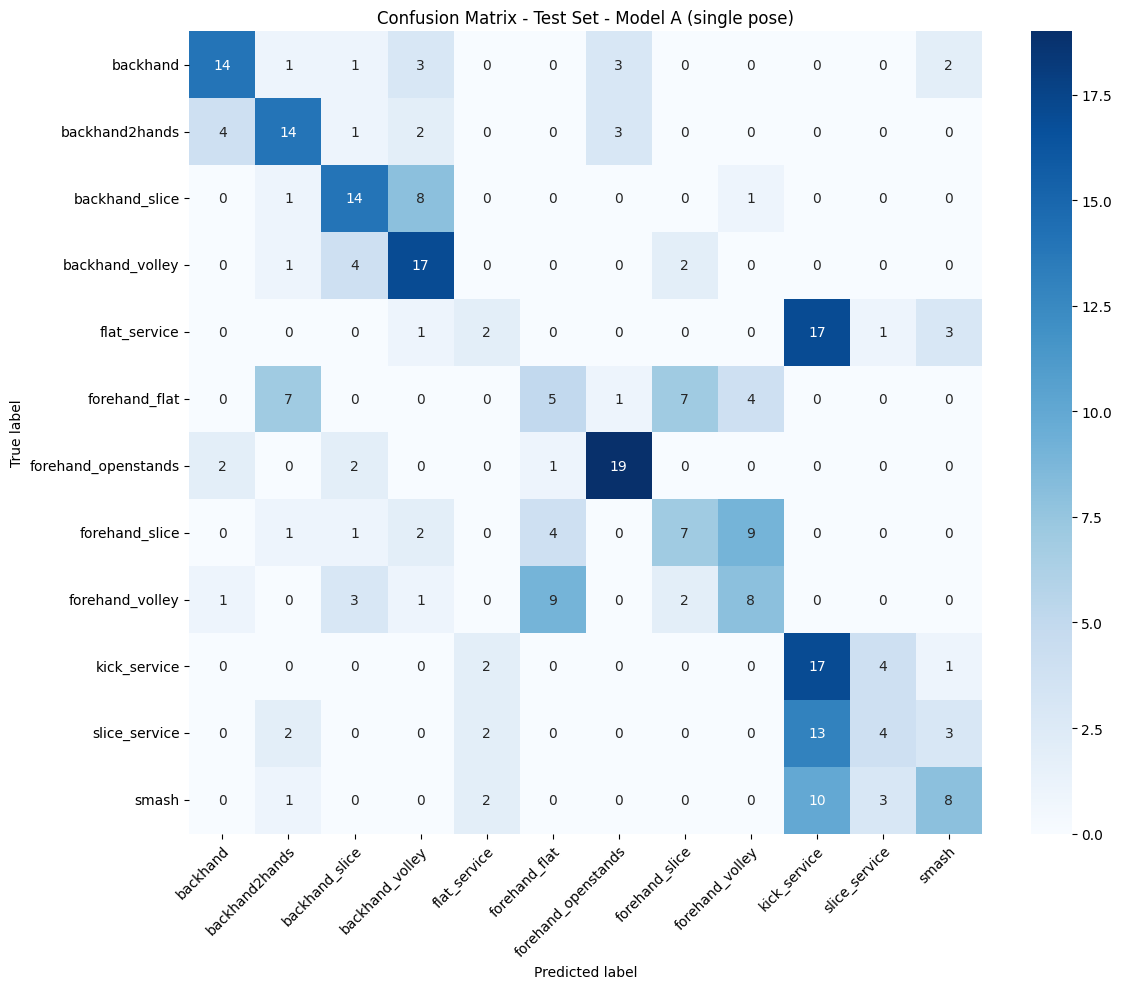

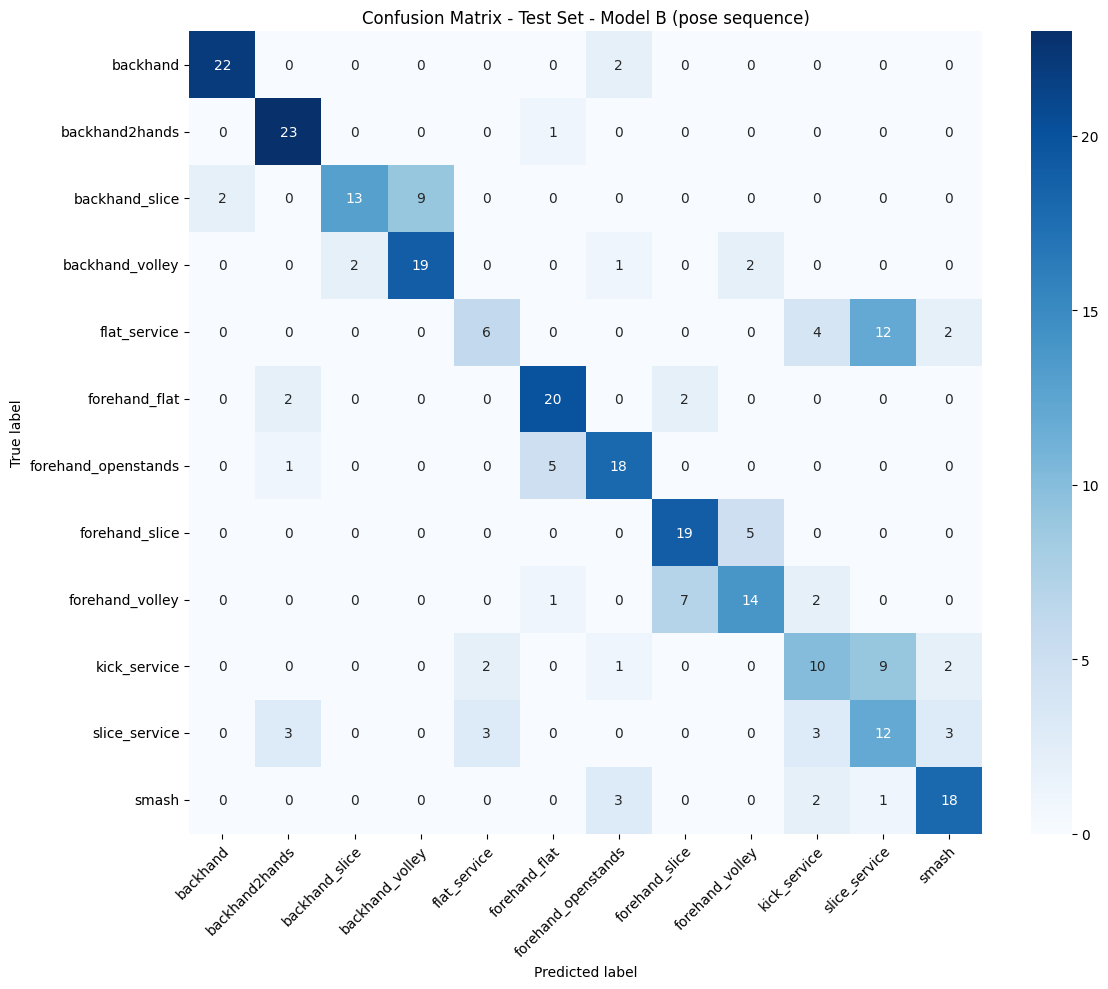

Most common mistakes of Model B (true -> predicted : count)
  flat_service -> slice_service : 12
  kick_service -> slice_service : 9
  backhand_slice -> backhand_volley : 9
  forehand_volley -> forehand_slice : 7
  forehand_slice -> forehand_volley : 5
  forehand_openstands -> forehand_flat : 5
  flat_service -> kick_service : 4
  smash -> forehand_openstands : 3

Saved to /content/results_skeleton: test_results_per_seed.csv, test_per_class_seed42.csv, confusion matrices (.png/.csv)


In [5]:
# =====================================================================
# PHASE 5 - FINISHING CELL (run in the SAME Colab session, right after the crashed cell)
# Uses the predictions that are already in memory (preds_store, rep, y_te).
# NOTHING is re-trained and the test set is NOT evaluated again.
# =====================================================================
pd.concat({t: pd.DataFrame({k: v for k, v in rep[t].items() if isinstance(v, dict)}).T for t in rep},
          axis=1).to_csv(f"{LOG_DIR}/test_per_class_seed42.csv")

for t, title in (("A", "Model A (single pose)"), ("B", "Model B (pose sequence)")):
    cm = confusion_matrix(y_te, preds_store[t], labels=list(range(12)))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{LOG_DIR}/test_confusion_{t}.csv")
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(f"Confusion Matrix - Test Set - {title}")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"); plt.tight_layout()
    fig.savefig(f"{LOG_DIR}/test_confusion_{t}.png", dpi=150, bbox_inches="tight"); plt.show()
    if t == "B":
        pairs = sorted([(cm[i, j], i, j) for i in range(12) for j in range(12) if i != j], reverse=True)[:8]
        print("Most common mistakes of Model B (true -> predicted : count)")
        for c, i, j in pairs: print(f"  {CLASS_NAMES[i]} -> {CLASS_NAMES[j]} : {c}")

with open(LOCK, "w") as f: f.write("Test set evaluated once. Do not re-run.")
print(f"\nSaved to {LOG_DIR}: test_results_per_seed.csv, test_per_class_seed42.csv, confusion matrices (.png/.csv)")

In [7]:
!cd /content && zip -rq skeleton_final.zip results_skeleton models_skeleton
!ls -lh /content/skeleton_final.zip
from google.colab import files
files.download("/content/skeleton_final.zip")

-rw-r--r-- 1 root root 5.6M Oct 10 19:56 /content/skeleton_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
!unzip skeleton_clean.zip

Archive:  skeleton_clean.zip
   creating: skeleton_clean/
   creating: skeleton_clean/kick_service/
  inflating: skeleton_clean/kick_service/p3_serkick_s1.npz  
  inflating: skeleton_clean/kick_service/p44_serkick_s3.npz  
  inflating: skeleton_clean/kick_service/p7_serkick_s3.npz  
  inflating: skeleton_clean/kick_service/p37_serkick_s1.npz  
  inflating: skeleton_clean/kick_service/p2_serkick_s2.npz  
  inflating: skeleton_clean/kick_service/p21_serkick_s1.npz  
  inflating: skeleton_clean/kick_service/p53_serkick_s2.npz  
  inflating: skeleton_clean/kick_service/p11_serkick_s1.npz  
  inflating: skeleton_clean/kick_service/p3_serkick_s3.npz  
  inflating: skeleton_clean/kick_service/p47_serkick_s3.npz  
  inflating: skeleton_clean/kick_service/p23_serkick_s2.npz  
  inflating: skeleton_clean/kick_service/p46_serkick_s1.npz  
  inflating: skeleton_clean/kick_service/p22_serkick_s2.npz  
  inflating: skeleton_clean/kick_service/p20_serkick_s3.npz  
  inflating: skeleton_clean/kick_ser